#Case Study: Sleep and Cognition ~
A Machine Learning Demonstration on an insomnia dataset of 100 people

+ The **Sleep Condition Indicator (SCI)** "is a measure of insomnia disorder over the past month. High scores indicate better sleep and scores of 16 and below indicate insomnia."

+ The **Pittsburgh Sleep Quality Index (PSQI)** "quantifies how well a subject sleeps in terms of interruptions, latency, and so on. A higher score indicates poorer sleep."

+ The **Epworth Sleepiness Scale (ESS)** "assesses daytime drowsiness. Higher scores indicate greater drowsiness."

###1. Problem Definition
Can we predict whether a subject has insomnia based on their SCI, PSQI and ESS scores and other data?

###2. Data Collection
In this stage, we will initialise our data object and install the necessary packages

In [1035]:
#All Imports
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error
import seaborn as sns
import scipy.stats as stats
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn import set_config
set_config(transform_output="pandas")

In [999]:
#Data
data = pd.read_csv('https://raw.githubusercontent.com/Rochelle784/data-engineering-and-analysis/refs/heads/main/datasets/gfmt_sleep.csv')

In [1000]:
data.head()

,participant number,gender,age,correct hit percentage,correct reject percentage,percent correct,confidence when correct hit,confidence when incorrect hit,confidence when correct reject,confidence when incorrect reject,confidence when correct,confidence when incorrect,sci,psqi,ess
0,8,f,39,65,80,72.5,91.0,90,93.0,83.5,93.0,90,9,13,2
1,16,m,42,90,90,90.0,75.5,55.5,70.5,50,75.0,50,4,11,7
2,18,f,31,90,95,92.5,89.5,90,86.0,81,89.0,88,10,9,3
3,22,f,35,100,75,87.5,89.5,*,71.0,80,88.0,80,13,8,20
4,27,f,74,60,65,62.5,68.5,49,61.0,49,65.0,49,13,9,12


###3. Data Pre-Processing
We will try to make sense of the data here so that certain values can be indexed easier in the future, and we will also somewhat clean the data too.

In [1001]:
#Null Values Investigation ~ There are no null values
data.isna().sum()

,0
participant number,0
gender,0
age,0
correct hit percentage,0
correct reject percentage,0
percent correct,0
confidence when correct hit,0
confidence when incorrect hit,0
confidence when correct reject,0
confidence when incorrect reject,0


In [1002]:
data.dtypes

,0
participant number,int64
gender,object
age,int64
correct hit percentage,int64
correct reject percentage,int64
percent correct,float64
confidence when correct hit,float64
confidence when incorrect hit,object
confidence when correct reject,float64
confidence when incorrect reject,object


### 4. Data Cleaning

Let's make a note of what seems strange to us if any
+ Do we need participant number?
+ Why is gender not a boolean datatype?
+ Why are some confidence values objects and some are floats?
+ Why do we not have a diagnosis column? (the most important column)

### As we can see, some columns are mostly numbers but with one or only a few strings that give it a different datatype

In [1003]:
data["confidence when incorrect hit"].unique()

array(['90', '55.5', '*', '49', '63', '56.5', '37', '76.5', '61.5',
       '75.5', '89', '50', '81', '56', '72', '77', '44.5', '57', '64',
       '83', '85', '43.5', '87.5', '70', '33', '29', '40', '55', '35.5',
       '67', '25', '28.5', '27', '53', '88', '32', '47', '83.5', '41',
       '73', '72.5', '30', '7', '43', '65', '47.5', '51.5', '38', '80',
       '68', '59.5', '52', '92', '66', '61', '75', '52.5', '66.5', '85.5'],
      dtype=object)

In [1004]:
data["confidence when incorrect reject"].unique()

array(['83.5', '50', '81', '80', '49', '72.5', '65', '81.5', '*', '69',
       '58.5', '68', '86', '73', '43.5', '60', '100', '67.5', '77', '54',
       '75', '53', '61', '21', '27', '52.5', '36', '66.5', '50.5', '59',
       '24', '63.5', '41.5', '45', '42.5', '91', '32', '78.5', '43', '29',
       '40', '70', '52', '53.5', '63', '70.5', '87', '83', '57', '17',
       '41', '74', '58', '89', '82', '65.5', '77.5', '82.5'], dtype=object)

In [1005]:
data["confidence when incorrect"].unique()

array(['90', '50', '88', '80', '49', '70.5', '64', '61', '76.5', '65',
       '75.5', '63', '59', '83.5', '56', '73', '60', '100', '73.5', '54',
       '67', '54.5', '83', '36', '67.5', '*', '70', '55.5', '44', '29',
       '57', '35.5', '24.5', '63.5', '35', '45', '53', '84', '91', '31',
       '51', '43', '76', '40', '79', '68', '58', '59.5', '47.5', '61.5',
       '55', '81', '71', '85', '82', '75', '74'], dtype=object)

### Let's start by removing the participant number

In [1006]:
data = data.drop(columns=["participant number"])

### Let's replace all the '*' values with the mean in the three columns we just looked at

In [1007]:
incorrect_hit = data[data["confidence when incorrect hit"] != '*']["confidence when incorrect hit"].astype("float")
incorrect_hit_mean = incorrect_hit.mean()
data["confidence when incorrect hit"] = data["confidence when incorrect hit"].replace("*", incorrect_hit_mean)
data["confidence when incorrect hit"] = data["confidence when incorrect hit"].astype("float").round(1)

In [1008]:
incorrect_reject = data[data["confidence when incorrect reject"] != "*"]["confidence when incorrect reject"].astype("float")
incorrect_reject_mean = incorrect_reject.mean()
data["confidence when incorrect reject"] = data["confidence when incorrect reject"].replace("*", incorrect_reject_mean)
data["confidence when incorrect reject"] = data["confidence when incorrect reject"].astype("float").round(1)

In [1009]:
incorrect = data[data["confidence when incorrect"] != "*"]["confidence when incorrect"].astype("float")
incorrect_mean = incorrect.mean()
data["confidence when incorrect"] = data["confidence when incorrect"].replace("*", incorrect_mean)
data["confidence when incorrect"] = data["confidence when incorrect"].astype("float").round(1)

In [1010]:
data.head()

,gender,age,correct hit percentage,correct reject percentage,percent correct,confidence when correct hit,confidence when incorrect hit,confidence when correct reject,confidence when incorrect reject,confidence when correct,confidence when incorrect,sci,psqi,ess
0,f,39,65,80,72.5,91.0,90.0,93.0,83.5,93.0,90.0,9,13,2
1,m,42,90,90,90.0,75.5,55.5,70.5,50.0,75.0,50.0,4,11,7
2,f,31,90,95,92.5,89.5,90.0,86.0,81.0,89.0,88.0,10,9,3
3,f,35,100,75,87.5,89.5,58.6,71.0,80.0,88.0,80.0,13,8,20
4,f,74,60,65,62.5,68.5,49.0,61.0,49.0,65.0,49.0,13,9,12


### Let's change the names of these columns to something a bit more appropriate

In [1011]:
data.columns = ["gender", "age", "correct_hit_perc", "correct_rej_perc", "correct_perc", "conf_correct_hit", "conf_incorrect_hit", "conf_correct_rej", "conf_incorrect_rej", "conf_correct", "conf_incorrect", "sci", "psqi", "ess"]

### Finally, we need to have a column that tells us whether the subject has insomnia
An SCI score below 16 tells us that the subject has probable insomnia disorder

In [1012]:
data["insomnia"] = [True if x <= 16 else False for x in data["sci"]]

### Make gender column categorical

In [1013]:
data["gender"] = data["gender"].astype("category")

### 5. Exploratory Data Analysis
Our data seems to be clean now and it is all numeric data aside from one column which we will leave as categorical data

In [1014]:
data.head(3)

,gender,age,correct_hit_perc,correct_rej_perc,correct_perc,conf_correct_hit,conf_incorrect_hit,conf_correct_rej,conf_incorrect_rej,conf_correct,conf_incorrect,sci,psqi,ess,insomnia
0,f,39,65,80,72.5,91.0,90.0,93.0,83.5,93.0,90.0,9,13,2,True
1,m,42,90,90,90.0,75.5,55.5,70.5,50.0,75.0,50.0,4,11,7,True
2,f,31,90,95,92.5,89.5,90.0,86.0,81.0,89.0,88.0,10,9,3,True


In [1015]:
data["gender"].value_counts()

,count
gender,
f,74
m,28


In [1016]:
data["insomnia"].value_counts()

,count
insomnia,
False,77
True,25


<Axes: xlabel='sci', ylabel='psqi'>

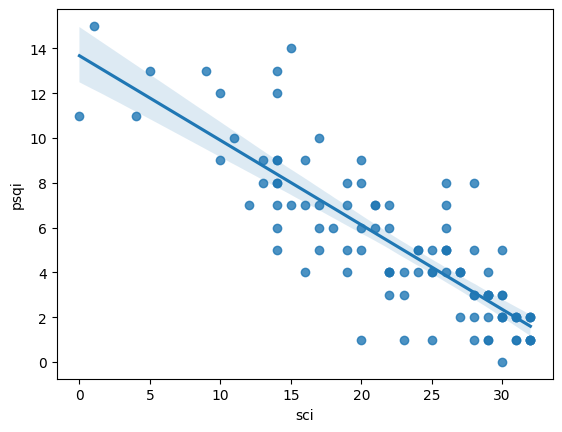

In [1017]:
sns.regplot(data, x="sci", y="psqi")

<Axes: xlabel='sci', ylabel='psqi'>

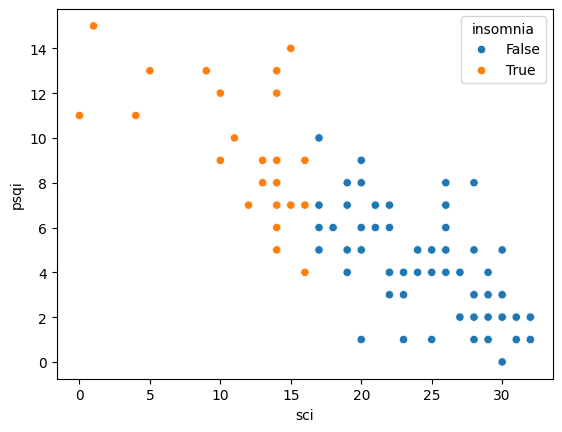

In [1018]:
sns.scatterplot(data, x="sci", y="psqi", hue="insomnia")

In [1019]:
data.columns

Index(['gender', 'age', 'correct_hit_perc', 'correct_rej_perc', 'correct_perc',
       'conf_correct_hit', 'conf_incorrect_hit', 'conf_correct_rej',
       'conf_incorrect_rej', 'conf_correct', 'conf_incorrect', 'sci', 'psqi',
       'ess', 'insomnia'],
      dtype='object')

In [1020]:
stats.shapiro(data["sci"]) #Not Normal Distribution

ShapiroResult(statistic=np.float64(0.9327705643217411), pvalue=np.float64(6.077301590332959e-05))

### 6. Split Training and Testing Data

In [1021]:
features = data.drop(columns=["sci", "insomnia"])
target = data[["insomnia"]]

In [1022]:
x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.3, stratify=target, random_state=31441234)

### 7. Encoding & Feature Engineering

In [ ]:
ohe = OneHotEncoder(sparse_output=False)
x_gender_train = ohe.fit_transform(x_train[["gender"]])
x_gender_test = ohe.transform(x_test[["gender"]])

en_x_train = pd.concat([x_gender_train, x_train.drop(columns=["gender"])], axis=1)
en_x_test = pd.concat([x_gender_test, x_test.drop(columns=["gender"])], axis=1)
# y_train
# y_test

### 8. Model Selection

In [1024]:
dtc = DecisionTreeClassifier(random_state=43, max_depth=2)

lg = LogisticRegression(max_iter=1000)

DecisionTreeClassifier(max_depth=2, random_state=43)

### 9. Model Training

In [1046]:
dtc.fit(en_x_train, y_train)

dtc.predict(en_x_train)

balanced_accuracy_score(y_test, dtc.predict(en_x_test))

np.float64(0.6005434782608696)

In [1045]:
lg.fit(en_x_train, y_train)

lg.predict(en_x_test)

balanced_accuracy_score(y_test, lg.predict(en_x_test))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


np.float64(0.7255434782608696)

### 10. Model Evaluation

In [1037]:
classification_report(y_test, lg.predict(en_x_test))

'              precision    recall  f1-score   support\n\n       False       0.86      0.83      0.84        23\n        True       0.56      0.62      0.59         8\n\n    accuracy                           0.77        31\n   macro avg       0.71      0.73      0.72        31\nweighted avg       0.78      0.77      0.78        31\n'

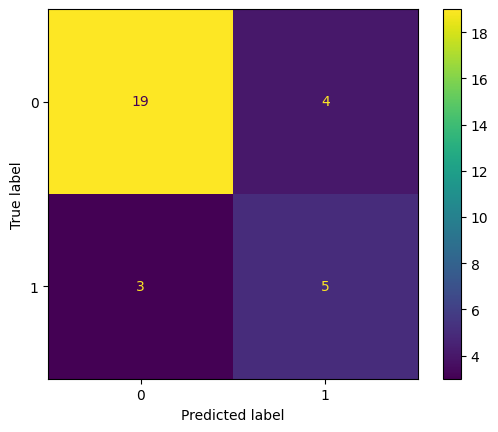

In [1047]:
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, lg.predict(en_x_test))
).plot();

<Axes: xlabel='sci', ylabel='psqi'>

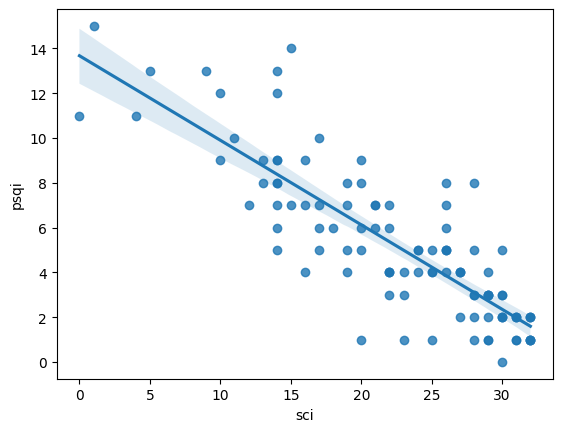

In [1064]:
sns.regplot(data, x="sci", y="psqi")

In [1054]:
#LogisticRegression Model (Binary Classification)
round(float(balanced_accuracy_score(y_test, lg.predict(en_x_test))), 4)

0.7255

In [1053]:
#LogisticRegression Model (Binary Classification)
round(float(accuracy_score(y_test, lg.predict(en_x_test))), 4)

0.7742